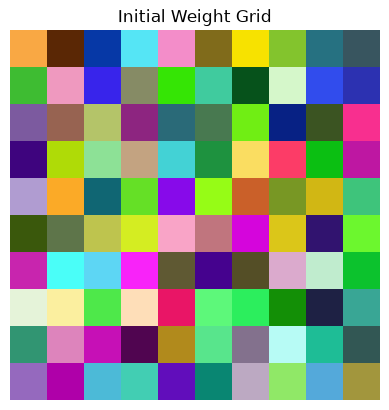

Data shape: (200, 3)
Data minimum: 0.00048793004329628076
Data maximum: 0.9963620786798558

Weight grid shape: (10, 10, 3)
Weight grid minimum: 0.0001587143305473715
Weight grid maximum: 0.9998865538125692


In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Task 1: Data and Weight Setup

# 1. Generate 200 random RGB colors
data = np.random.rand(200, 3)

# 2. Create a 10 x 10 grid of neurons
# Each neuron has 3 weights: R, G, B
weights = np.random.rand(10, 10, 3)

# 3. Display initial weight grid as an image
plt.imshow(weights)
plt.title("Initial Weight Grid")
plt.axis("off")
plt.show()

# 4. Print shape, minimum and maximum values
print("Data shape:", data.shape)
print("Data minimum:", data.min())
print("Data maximum:", data.max())

print("\nWeight grid shape:", weights.shape)
print("Weight grid minimum:", weights.min())
print("Weight grid maximum:", weights.max())

Selected sample: [0.73516395 0.87942471 0.46479258]
Distance array shape: (10, 10)


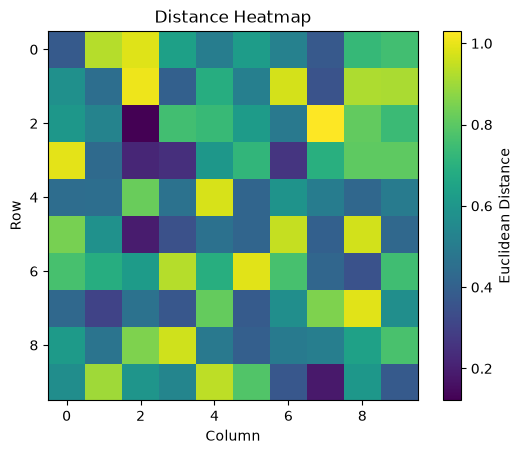

Smallest distance: 0.12108267152675252
BMU position (row, column): (np.int64(2), np.int64(2))


In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Task 2: Distance Calculation

# 1. Euclidean distance function
def euclidean_distance(a, b):
    return np.sqrt(np.sum((a - b) ** 2))


# 2. Pick one random sample from data
random_index = np.random.randint(len(data))
sample = data[random_index]

print("Selected sample:", sample)

# Compute distance from this sample to every neuron
# weights shape = (10, 10, 3)
distances = np.sqrt(np.sum((weights - sample) ** 2, axis=2))

print("Distance array shape:", distances.shape)


# 3. Display distance array as heatmap
plt.imshow(distances)
plt.colorbar(label="Euclidean Distance")
plt.title("Distance Heatmap")
plt.xlabel("Column")
plt.ylabel("Row")
plt.show()


# 4. Find smallest distance and its location
min_distance = distances.min()

min_position = np.unravel_index(
    np.argmin(distances),
    distances.shape
)

print("Smallest distance:", min_distance)
print("BMU position (row, column):", min_position)

Sample 1 | BMU: (np.int64(8), np.int64(7)) | Distance: 0.1945
Sample 2 | BMU: (np.int64(6), np.int64(9)) | Distance: 0.1029
Sample 3 | BMU: (np.int64(3), np.int64(6)) | Distance: 0.0733
Sample 4 | BMU: (np.int64(4), np.int64(2)) | Distance: 0.0659
Sample 5 | BMU: (np.int64(8), np.int64(3)) | Distance: 0.1786


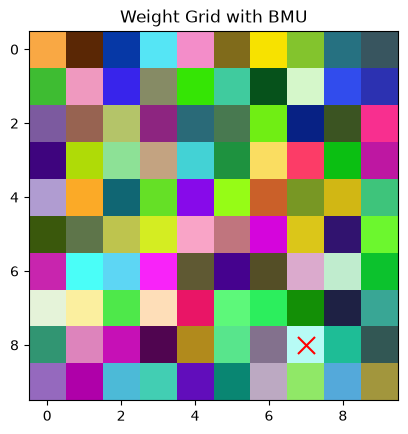

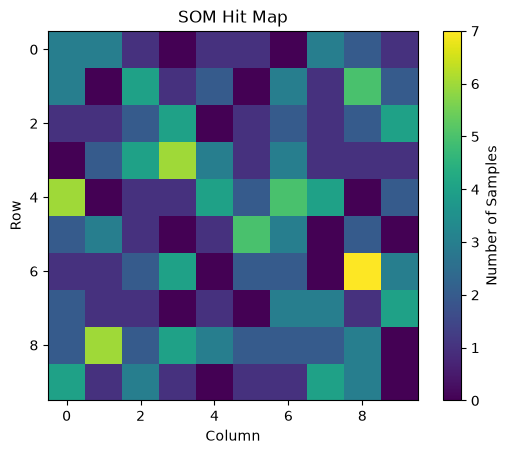

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Task 3: Finding the Winner (BMU)

# 1. Function to find Best Matching Unit
def find_bmu(weights, x):
    distances = np.sqrt(np.sum((weights - x) ** 2, axis=2))
    bmu = np.unravel_index(np.argmin(distances), distances.shape)
    return bmu


# 2. Find BMU for 5 samples
for i in range(5):
    sample = data[i]

    bmu = find_bmu(weights, sample)

    distance = np.linalg.norm(
        sample - weights[bmu]
    )

    print(
        f"Sample {i+1} | "
        f"BMU: {bmu} | "
        f"Distance: {distance:.4f}"
    )


# 3. Display weight grid and mark BMU of one sample
sample = data[0]

bmu = find_bmu(weights, sample)

plt.imshow(weights)

# scatter uses x = column, y = row
plt.scatter(
    bmu[1],
    bmu[0],
    color="red",
    marker="x",
    s=150
)

plt.title("Weight Grid with BMU")
plt.show()


# 4. Find BMU of all 200 samples
hit_map = np.zeros((10, 10))

for sample in data:
    bmu = find_bmu(weights, sample)
    hit_map[bmu] += 1


# Display hit map
plt.imshow(hit_map)

plt.colorbar(label="Number of Samples")

plt.title("SOM Hit Map")
plt.xlabel("Column")
plt.ylabel("Row")

plt.show()

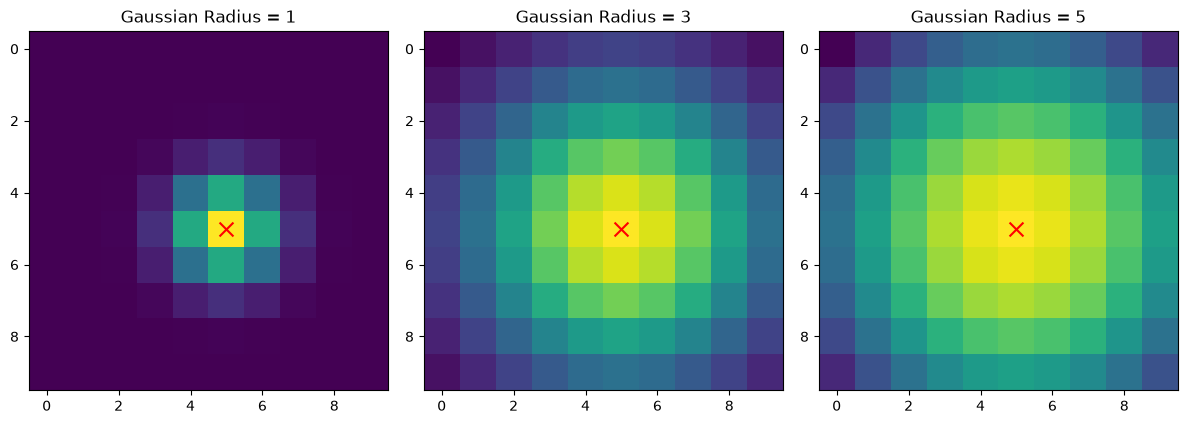

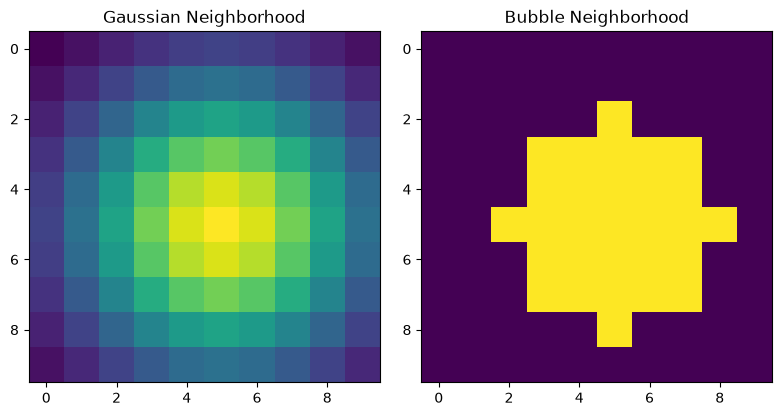

Value at BMU: 1.0
Value 3 steps away: 0.32465246735834974


In [4]:
import numpy as np
import matplotlib.pyplot as plt

# Task 4: Neighborhood Function

# 1. Gaussian neighborhood function
def neighborhood(grid_size, bmu, radius):
    rows, cols = np.indices((grid_size, grid_size))

    distance_squared = (
        (rows - bmu[0]) ** 2 +
        (cols - bmu[1]) ** 2
    )

    h = np.exp(-distance_squared / (2 * radius ** 2))

    return h


# 2. Plot Gaussian neighborhood for radius 1, 3 and 5
bmu = (5, 5)

radii = [1, 3, 5]

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, radius in zip(axes, radii):

    h = neighborhood(10, bmu, radius)

    im = ax.imshow(h)
    ax.set_title(f"Gaussian Radius = {radius}")

    ax.scatter(
        bmu[1],
        bmu[0],
        color="red",
        marker="x",
        s=100
    )

plt.tight_layout()
plt.show()


# 3. Bubble neighborhood function
def bubble_neighborhood(grid_size, bmu, radius):

    rows, cols = np.indices((grid_size, grid_size))

    distance = np.sqrt(
        (rows - bmu[0]) ** 2 +
        (cols - bmu[1]) ** 2
    )

    h = (distance <= radius).astype(float)

    return h


# Compare Gaussian and Bubble neighborhood
radius = 3

gaussian_h = neighborhood(10, bmu, radius)
bubble_h = bubble_neighborhood(10, bmu, radius)

fig, axes = plt.subplots(1, 2, figsize=(8, 4))

axes[0].imshow(gaussian_h)
axes[0].set_title("Gaussian Neighborhood")

axes[1].imshow(bubble_h)
axes[1].set_title("Bubble Neighborhood")

plt.tight_layout()
plt.show()


# 4. Print h at BMU and 3 steps away
radius = 2

h = neighborhood(10, bmu, radius)

print("Value at BMU:", h[5, 5])

# Neuron 3 steps away from BMU
print("Value 3 steps away:", h[5, 8])

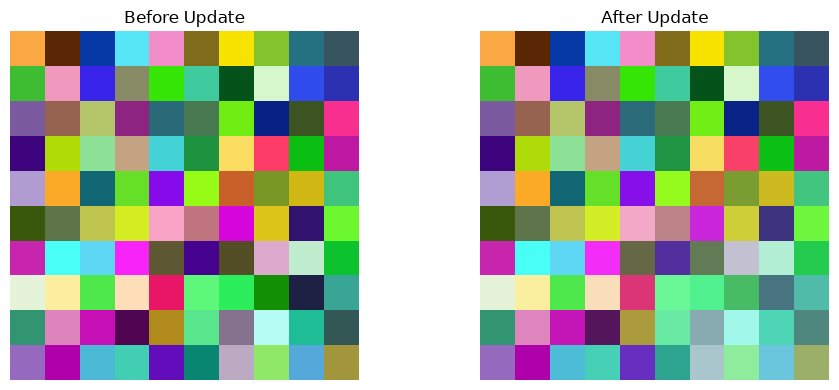

Total absolute weight change: 8.891153959299672
Distance before update: 0.19450524456652596
Distance after update: 0.09725262228326297
Distance decreased successfully.


In [5]:
import numpy as np
import matplotlib.pyplot as plt

# Task 5: One Weight Update Step

# Gaussian neighborhood function
def neighborhood(grid_size, bmu, radius):
    rows, cols = np.indices((grid_size, grid_size))

    distance_squared = (
        (rows - bmu[0]) ** 2 +
        (cols - bmu[1]) ** 2
    )

    h = np.exp(-distance_squared / (2 * radius ** 2))

    return h


# 1. Function to update weights once
def update_weights(weights, x, bmu, learning_rate, radius):

    h = neighborhood(weights.shape[0], bmu, radius)

    new_weights = weights.copy()

    new_weights += (
        learning_rate *
        h[:, :, np.newaxis] *
        (x - new_weights)
    )

    return new_weights


# Pick one sample
sample = data[0]

# Find its BMU
bmu = find_bmu(weights, sample)

learning_rate = 0.5
radius = 2


# Distance BEFORE update
distance_before = np.linalg.norm(
    sample - weights[bmu]
)


# Save old weights
weights_before = weights.copy()


# Apply one update
weights_after = update_weights(
    weights,
    sample,
    bmu,
    learning_rate,
    radius
)


# 2. Show before and after weight grids
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].imshow(weights_before)
axes[0].set_title("Before Update")
axes[0].axis("off")

axes[1].imshow(weights_after)
axes[1].set_title("After Update")
axes[1].axis("off")

plt.tight_layout()
plt.show()


# 3. Total absolute change in weights
total_change = np.sum(
    np.abs(weights_after - weights_before)
)

print("Total absolute weight change:", total_change)


# 4. Distance AFTER update
distance_after = np.linalg.norm(
    sample - weights_after[bmu]
)

print("Distance before update:", distance_before)
print("Distance after update:", distance_after)


# Confirm that distance decreased
if distance_after < distance_before:
    print("Distance decreased successfully.")
else:
    print("Distance did not decrease.")

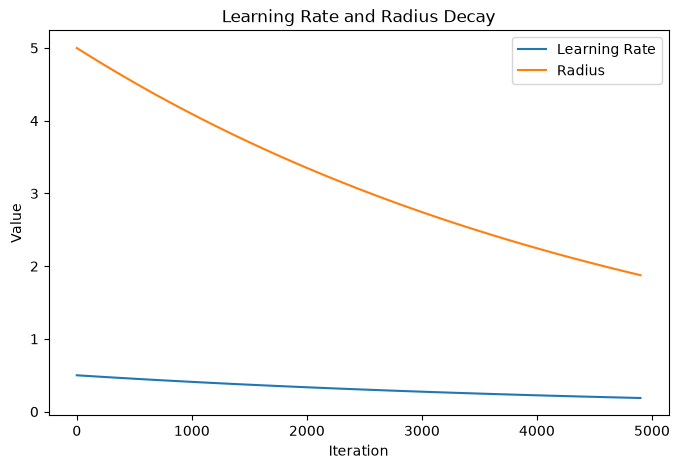

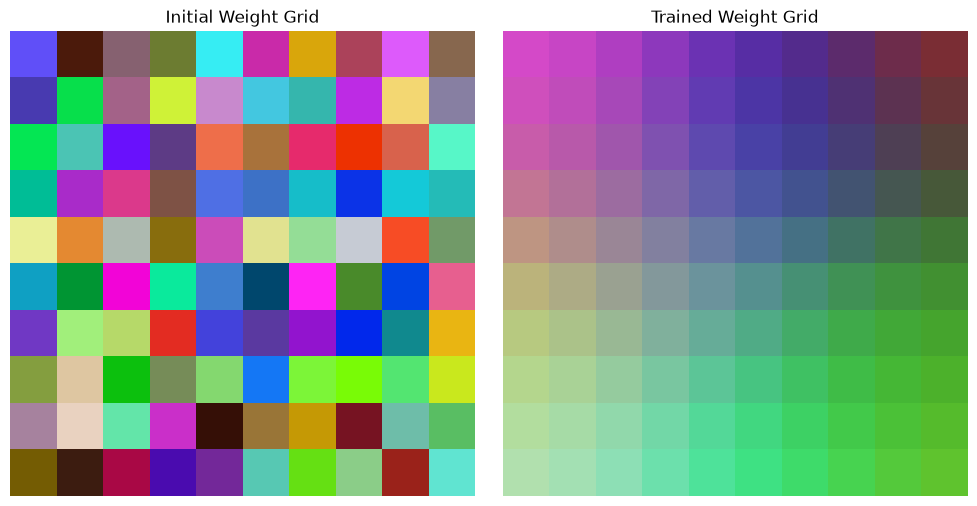

In [6]:
import numpy as np
import matplotlib.pyplot as plt

# Task 6: Training Loop


# Find Best Matching Unit (BMU)
def find_bmu(weights, x):
    distances = np.sqrt(np.sum((weights - x) ** 2, axis=2))
    return np.unravel_index(np.argmin(distances), distances.shape)


# Gaussian neighborhood
def neighborhood(grid_size, bmu, radius):
    rows, cols = np.indices((grid_size, grid_size))

    distance_squared = (
        (rows - bmu[0]) ** 2 +
        (cols - bmu[1]) ** 2
    )

    return np.exp(-distance_squared / (2 * radius ** 2))


# Update weights
def update_weights(weights, x, bmu, learning_rate, radius):

    h = neighborhood(weights.shape[0], bmu, radius)

    weights += (
        learning_rate *
        h[:, :, np.newaxis] *
        (x - weights)
    )

    return weights


# 1. SOM Training Function
def train_som(data, grid_size, iterations, lr_start, radius_start):

    # Random initial weights
    weights = np.random.rand(grid_size, grid_size, 3)

    # Save initial weights
    initial_weights = weights.copy()

    # Lists for learning rate and radius
    lr_history = []
    radius_history = []
    iteration_history = []

    for i in range(iterations):

        # Exponential decay
        learning_rate = lr_start * np.exp(-i / iterations)
        radius = radius_start * np.exp(-i / iterations)

        # Select random sample
        x = data[np.random.randint(len(data))]

        # Find BMU
        bmu = find_bmu(weights, x)

        # Update weights
        weights = update_weights(
            weights,
            x,
            bmu,
            learning_rate,
            radius
        )

        # 2. Store learning rate and radius every 100 iterations
        if i % 100 == 0:
            lr_history.append(learning_rate)
            radius_history.append(radius)
            iteration_history.append(i)

    return (
        initial_weights,
        weights,
        lr_history,
        radius_history,
        iteration_history
    )


# Train SOM
initial_weights, trained_weights, lr_history, radius_history, iteration_history = train_som(
    data=data,
    grid_size=10,
    iterations=5000,
    lr_start=0.5,
    radius_start=5
)


# 3. Plot learning rate and radius
plt.figure(figsize=(8, 5))

plt.plot(iteration_history, lr_history, label="Learning Rate")
plt.plot(iteration_history, radius_history, label="Radius")

plt.xlabel("Iteration")
plt.ylabel("Value")
plt.title("Learning Rate and Radius Decay")
plt.legend()

plt.show()


# 4. Show initial and trained weight grids
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(initial_weights)
axes[0].set_title("Initial Weight Grid")
axes[0].axis("off")

axes[1].imshow(trained_weights)
axes[1].set_title("Trained Weight Grid")
axes[1].axis("off")

plt.tight_layout()

# Save figure
plt.savefig("task6_result.png")

plt.show()

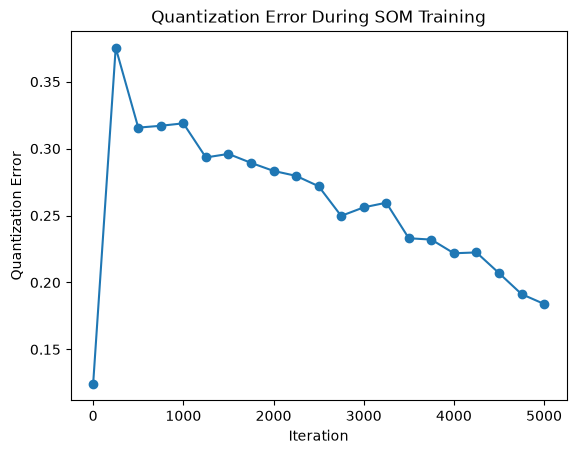

First Error: 0.1243862343272021
Last Error: 0.1839632520918585
Percentage Reduction: -47.89679347309211 %


In [7]:
import numpy as np
import matplotlib.pyplot as plt

# Task 7: Measuring Training Quality


# Find BMU
def find_bmu(weights, x):
    distances = np.sqrt(np.sum((weights - x) ** 2, axis=2))
    return np.unravel_index(np.argmin(distances), distances.shape)


# Gaussian neighborhood
def neighborhood(grid_size, bmu, radius):
    rows, cols = np.indices((grid_size, grid_size))

    distance_squared = (
        (rows - bmu[0]) ** 2 +
        (cols - bmu[1]) ** 2
    )

    return np.exp(-distance_squared / (2 * radius ** 2))


# Update weights
def update_weights(weights, x, bmu, learning_rate, radius):
    h = neighborhood(weights.shape[0], bmu, radius)

    weights += (
        learning_rate *
        h[:, :, np.newaxis] *
        (x - weights)
    )

    return weights


# 1. Quantization Error Function
def quantization_error(data, weights):

    total_error = 0

    for x in data:
        bmu = find_bmu(weights, x)

        distance = np.linalg.norm(
            x - weights[bmu]
        )

        total_error += distance

    return total_error / len(data)


# 2. Modified training function
def train_som(
    data,
    grid_size,
    iterations,
    lr_start,
    radius_start
):

    weights = np.random.rand(
        grid_size,
        grid_size,
        3
    )

    error_history = []
    error_iterations = []

    # Record initial error
    error_history.append(
        quantization_error(data, weights)
    )
    error_iterations.append(0)

    for i in range(1, iterations + 1):

        # Exponential decay
        learning_rate = (
            lr_start * np.exp(-i / iterations)
        )

        radius = (
            radius_start * np.exp(-i / iterations)
        )

        # Select random sample
        x = data[
            np.random.randint(len(data))
        ]

        # Find BMU
        bmu = find_bmu(weights, x)

        # Update weights
        weights = update_weights(
            weights,
            x,
            bmu,
            learning_rate,
            radius
        )

        # Record error every 250 iterations
        if i % 250 == 0:

            error = quantization_error(
                data,
                weights
            )

            error_history.append(error)
            error_iterations.append(i)

    return (
        weights,
        error_history,
        error_iterations
    )


# Train SOM
trained_weights, error_history, error_iterations = train_som(
    data=data,
    grid_size=10,
    iterations=5000,
    lr_start=0.5,
    radius_start=5
)


# 3. Plot Quantization Error
plt.plot(
    error_iterations,
    error_history,
    marker="o"
)

plt.xlabel("Iteration")
plt.ylabel("Quantization Error")
plt.title("Quantization Error During SOM Training")

plt.show()


# 4. Print first error, last error and percentage reduction
first_error = error_history[0]
last_error = error_history[-1]

percentage_reduction = (
    (first_error - last_error)
    / first_error
) * 100


print("First Error:", first_error)
print("Last Error:", last_error)
print(
    "Percentage Reduction:",
    percentage_reduction,
    "%"
)

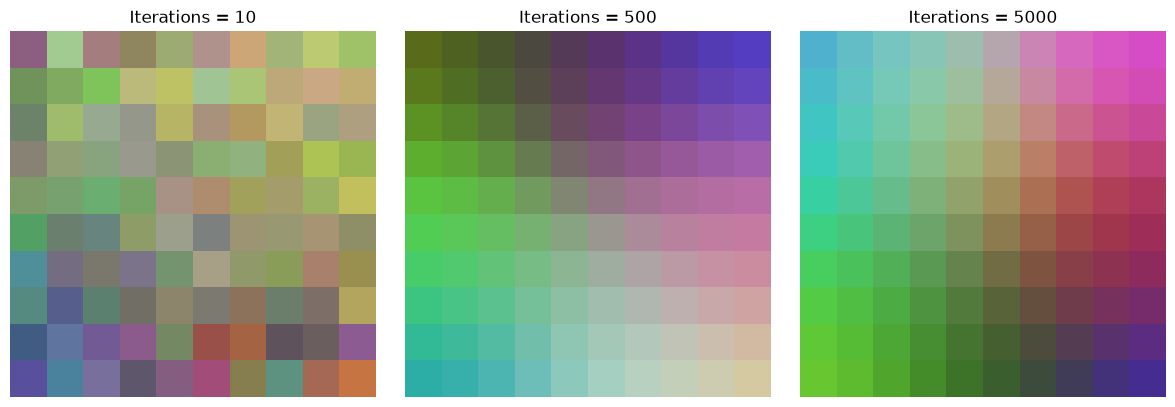

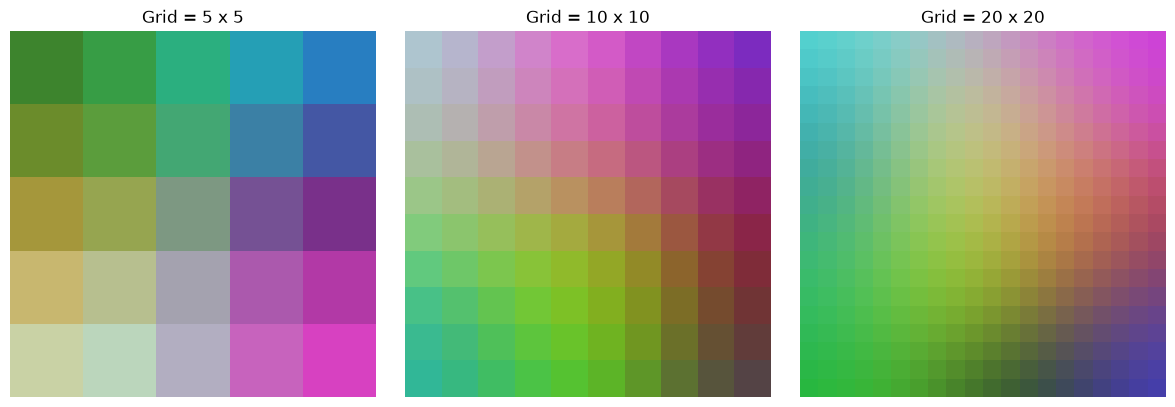

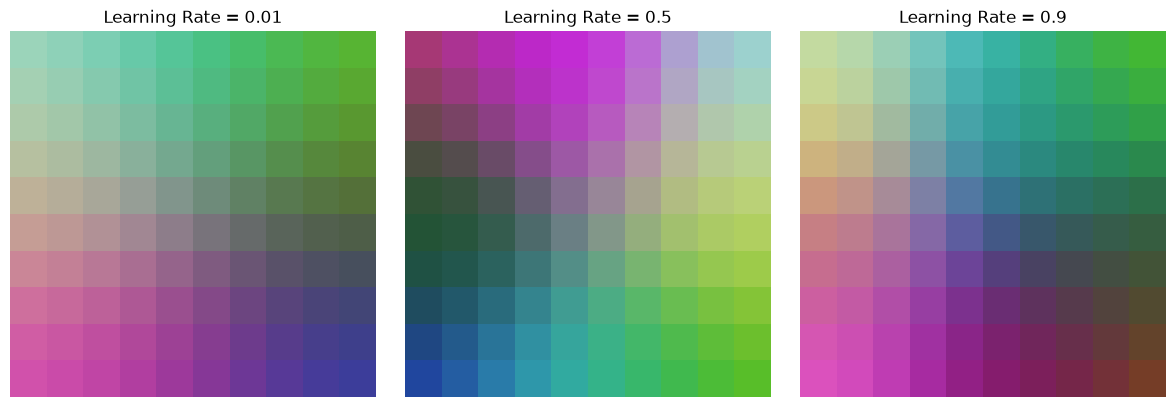


Summary Table
 Setting Name   Value  Final Error
   Iterations   10.00     0.269190
   Iterations  500.00     0.213318
   Iterations 5000.00     0.196058
    Grid Size    5.00     0.215375
    Grid Size   10.00     0.196560
    Grid Size   20.00     0.174466
Learning Rate    0.01     0.228651
Learning Rate    0.50     0.185205
Learning Rate    0.90     0.198094


In [8]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Task 8: Parameter Experiments


# ---------- Helper Functions ----------

def find_bmu(weights, x):
    distances = np.sqrt(np.sum((weights - x) ** 2, axis=2))
    return np.unravel_index(np.argmin(distances), distances.shape)


def neighborhood(grid_size, bmu, radius):
    rows, cols = np.indices((grid_size, grid_size))

    distance_squared = (
        (rows - bmu[0]) ** 2 +
        (cols - bmu[1]) ** 2
    )

    return np.exp(
        -distance_squared / (2 * radius ** 2)
    )


def update_weights(weights, x, bmu, learning_rate, radius):

    h = neighborhood(
        weights.shape[0],
        bmu,
        radius
    )

    weights += (
        learning_rate *
        h[:, :, np.newaxis] *
        (x - weights)
    )

    return weights


def train_som(data, grid_size, iterations, lr_start, radius_start):

    weights = np.random.rand(
        grid_size,
        grid_size,
        3
    )

    for i in range(iterations):

        learning_rate = (
            lr_start *
            np.exp(-i / iterations)
        )

        radius = (
            radius_start *
            np.exp(-i / iterations)
        )

        x = data[
            np.random.randint(len(data))
        ]

        bmu = find_bmu(weights, x)

        weights = update_weights(
            weights,
            x,
            bmu,
            learning_rate,
            radius
        )

    return weights


def quantization_error(data, weights):

    total_error = 0

    for x in data:

        bmu = find_bmu(weights, x)

        total_error += np.linalg.norm(
            x - weights[bmu]
        )

    return total_error / len(data)


# Store experiment results
results = []


# =====================================================
# 1. Experiment with different number of iterations
# =====================================================

iteration_values = [10, 500, 5000]

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, iterations in zip(axes, iteration_values):

    weights = train_som(
        data,
        grid_size=10,
        iterations=iterations,
        lr_start=0.5,
        radius_start=5
    )

    ax.imshow(weights)
    ax.set_title(f"Iterations = {iterations}")
    ax.axis("off")

    error = quantization_error(data, weights)

    results.append([
        "Iterations",
        iterations,
        error
    ])

plt.tight_layout()
plt.show()


# =====================================================
# 2. Experiment with different grid sizes
# =====================================================

grid_sizes = [5, 10, 20]

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, grid_size in zip(axes, grid_sizes):

    weights = train_som(
        data,
        grid_size=grid_size,
        iterations=5000,
        lr_start=0.5,
        radius_start=grid_size / 2
    )

    ax.imshow(weights)
    ax.set_title(f"Grid = {grid_size} x {grid_size}")
    ax.axis("off")

    error = quantization_error(data, weights)

    results.append([
        "Grid Size",
        grid_size,
        error
    ])

plt.tight_layout()
plt.show()


# =====================================================
# 3. Experiment with different learning rates
# =====================================================

learning_rates = [0.01, 0.5, 0.9]

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, lr in zip(axes, learning_rates):

    weights = train_som(
        data,
        grid_size=10,
        iterations=5000,
        lr_start=lr,
        radius_start=5
    )

    ax.imshow(weights)
    ax.set_title(f"Learning Rate = {lr}")
    ax.axis("off")

    error = quantization_error(data, weights)

    results.append([
        "Learning Rate",
        lr,
        error
    ])

plt.tight_layout()
plt.show()


# =====================================================
# 4. Summary Table
# =====================================================

summary_table = pd.DataFrame(
    results,
    columns=[
        "Setting Name",
        "Value",
        "Final Error"
    ]
)

print("\nSummary Table")
print(summary_table.to_string(index=False))

Data shape: (100, 3)


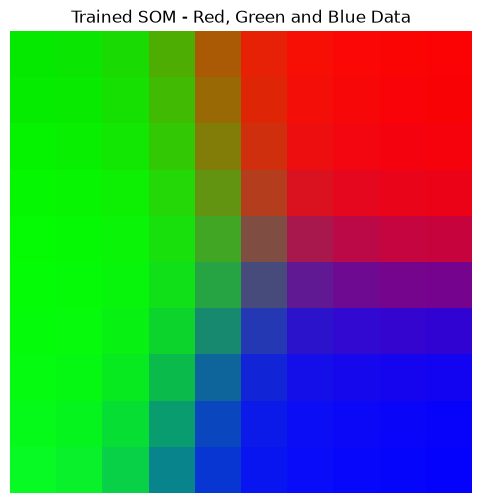

BMU: (np.int64(1), np.int64(9)) | Number of samples: 3
BMU: (np.int64(0), np.int64(9)) | Number of samples: 14
BMU: (np.int64(0), np.int64(6)) | Number of samples: 7
BMU: (np.int64(3), np.int64(8)) | Number of samples: 2
BMU: (np.int64(0), np.int64(5)) | Number of samples: 1
BMU: (np.int64(1), np.int64(6)) | Number of samples: 1
BMU: (np.int64(3), np.int64(9)) | Number of samples: 2
BMU: (np.int64(2), np.int64(9)) | Number of samples: 1
BMU: (np.int64(2), np.int64(7)) | Number of samples: 1
BMU: (np.int64(3), np.int64(7)) | Number of samples: 1
BMU: (np.int64(0), np.int64(8)) | Number of samples: 1
BMU: (np.int64(1), np.int64(0)) | Number of samples: 3
BMU: (np.int64(4), np.int64(0)) | Number of samples: 9
BMU: (np.int64(9), np.int64(0)) | Number of samples: 3
BMU: (np.int64(7), np.int64(0)) | Number of samples: 2
BMU: (np.int64(7), np.int64(2)) | Number of samples: 1
BMU: (np.int64(2), np.int64(0)) | Number of samples: 1
BMU: (np.int64(0), np.int64(0)) | Number of samples: 3
BMU: (np.

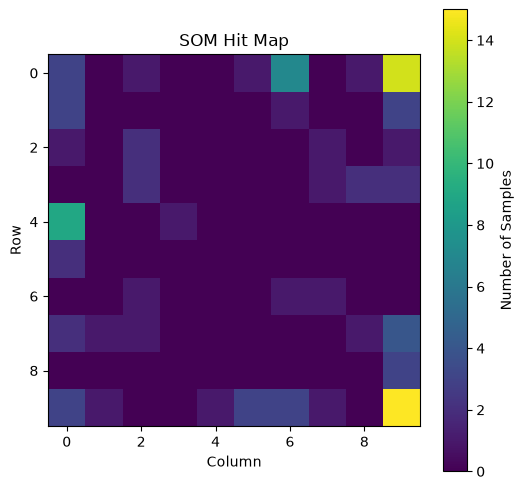

In [9]:
import numpy as np
import matplotlib.pyplot as plt

# =====================================================
# Task 9: Mini Project with Your Own Data
# =====================================================

# ---------- Helper Functions ----------

def find_bmu(weights, x):
    distances = np.sqrt(np.sum((weights - x) ** 2, axis=2))
    return np.unravel_index(np.argmin(distances), distances.shape)


def neighborhood(grid_size, bmu, radius):
    rows, cols = np.indices((grid_size, grid_size))

    distance_squared = (
        (rows - bmu[0]) ** 2 +
        (cols - bmu[1]) ** 2
    )

    return np.exp(
        -distance_squared / (2 * radius ** 2)
    )


def train_som(data, grid_size=10, iterations=5000,
              lr_start=0.5, radius_start=5):

    weights = np.random.rand(grid_size, grid_size, 3)

    for i in range(iterations):

        # Exponential decay
        learning_rate = lr_start * np.exp(-i / iterations)
        radius = radius_start * np.exp(-i / iterations)

        # Pick random sample
        x = data[np.random.randint(len(data))]

        # Find BMU
        bmu = find_bmu(weights, x)

        # Neighborhood values
        h = neighborhood(grid_size, bmu, radius)

        # Update weights
        weights += (
            learning_rate *
            h[:, :, np.newaxis] *
            (x - weights)
        )

    return weights


# =====================================================
# 1. Generate 100 samples near Red, Green and Blue
# =====================================================

np.random.seed(42)

red = np.array([1, 0, 0])
green = np.array([0, 1, 0])
blue = np.array([0, 0, 1])

# Generate 34 red, 33 green, 33 blue = 100 samples
red_samples = red + np.random.normal(0, 0.08, (34, 3))
green_samples = green + np.random.normal(0, 0.08, (33, 3))
blue_samples = blue + np.random.normal(0, 0.08, (33, 3))

# Combine samples
data = np.vstack([
    red_samples,
    green_samples,
    blue_samples
])

# Keep all RGB values between 0 and 1
data = np.clip(data, 0, 1)

print("Data shape:", data.shape)


# =====================================================
# 2. Train 10 x 10 SOM
# =====================================================

trained_weights = train_som(
    data,
    grid_size=10,
    iterations=5000,
    lr_start=0.5,
    radius_start=5
)

# Display trained SOM
plt.figure(figsize=(6, 6))

plt.imshow(trained_weights)

plt.title("Trained SOM - Red, Green and Blue Data")
plt.axis("off")

plt.show()


# =====================================================
# 3. Find BMU of every sample and group using dictionary
# =====================================================

groups = {}

for sample in data:

    bmu = find_bmu(trained_weights, sample)

    if bmu not in groups:
        groups[bmu] = []

    groups[bmu].append(sample)


# Print groups
for bmu, samples in groups.items():
    print(
        "BMU:",
        bmu,
        "| Number of samples:",
        len(samples)
    )


# =====================================================
# 4. Number of active neurons + Hit Map
# =====================================================

active_neurons = len(groups)

print("\nNumber of neurons that received at least one sample:",
      active_neurons)


# Create hit map
hit_map = np.zeros((10, 10))

for bmu, samples in groups.items():
    hit_map[bmu] = len(samples)


# Plot hit map
plt.figure(figsize=(6, 6))

plt.imshow(hit_map)

plt.colorbar(label="Number of Samples")

plt.title("SOM Hit Map")
plt.xlabel("Column")
plt.ylabel("Row")

plt.show()